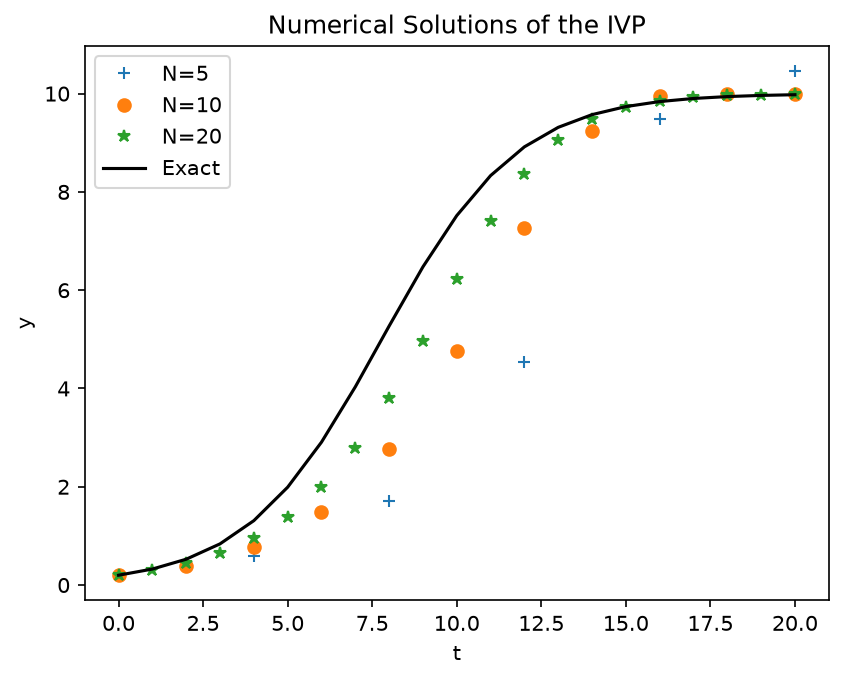

In [ ]:
import numpy as np
def Dynamics(t, y):
    return (y/20)*(10-y)

def ExactVal(t):
    return 10/(49*np.exp(-t/2)+1)

def ForwardEuler(t0, tfinal, N, y0):
    h = (tfinal-t0)/N
    y = np.zeros(N+1)
    y[0] = y0
    for i in range(N):
        t_i = t0+i*h
        y[i+1] = y[i]+h*Dynamics(t_i, y[i])
    return y

import matplotlib.pyplot as plt
t0 = 0
tfinal = 20
N1 = 5
N2 = 10
N3 = 20
y0 = 1/5
for N in [N1, N2, N3]:
    y = ForwardEuler(t0, tfinal, N, y0)
    t = np.linspace(t0, tfinal, N+1)
    plt.plot(t, y, linestyle='None', marker='+' if N==N1 else 'o' if N==N2 else '*', label=f'N={N}')
t_exact = np.linspace(t0, tfinal, N3+1)
y_exact = ExactVal(t_exact)
plt.plot(t_exact, y_exact, label='Exact', color='black')
plt.xlabel('t')
plt.ylabel('y')
plt.title('Numerical Solutions of the IVP')
plt.legend()
plt.show()


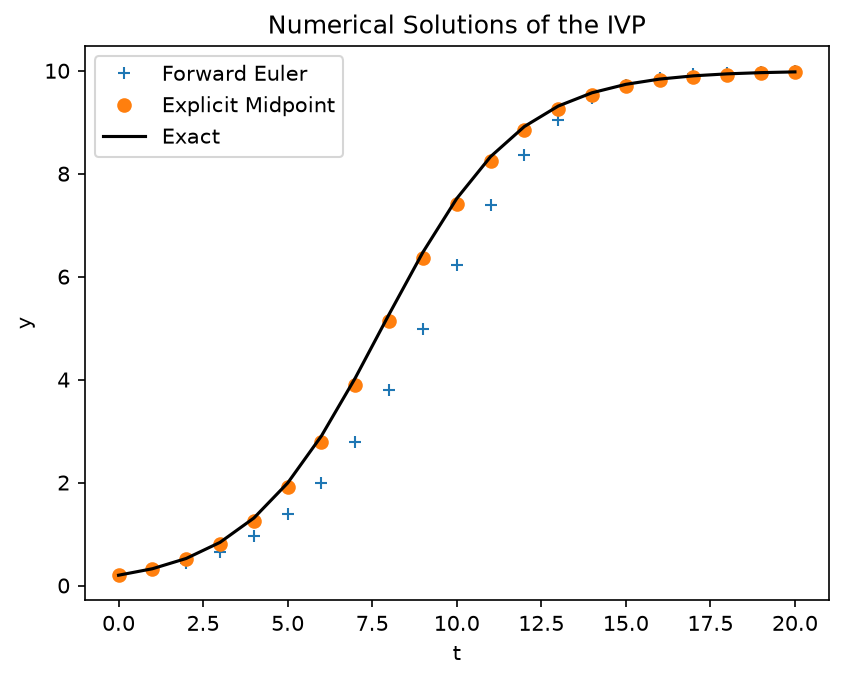

In [5]:
def ExplicitMidpoint(t0, tfinal, N, y0):
    h = (tfinal-t0)/N
    y = np.zeros(N+1)
    y[0] = y0
    for i in range(N):
        t_i = t0+i*h
        k1 = Dynamics(t_i, y[i])
        k2 = Dynamics(t_i + h/2, y[i] + h*k1/2)
        y[i+1] = y[i] + h*k2
    return y  
N = 20
y_fe = ForwardEuler(t0, tfinal, N, y0)
y_mp = ExplicitMidpoint(t0, tfinal, N, y0)
t = np.linspace(t0, tfinal, N+1)
plt.plot(t, y_fe, linestyle='None', marker='+', label='Forward Euler')
plt.plot(t, y_mp, linestyle='None', marker='o', label='Explicit Midpoint')
plt.plot(t, ExactVal(t), label='Exact', color='black')
plt.xlabel('t')
plt.ylabel('y')
plt.title('Numerical Solutions of the IVP')
plt.legend()
plt.show()

In [8]:
print("i\terr(h)\terr(h/2)/err(h)")
tfinal = 10
prev_err = None
for i in range(10):
    N = 5 * 2**i
    y_fe = ForwardEuler(t0, tfinal, N, y0)
    err = abs(y_fe[-1] - ExactVal(tfinal))
    if prev_err is None:
        print(f"{i}\t{err:.2e}\t-")
    else:
        ratio = err / prev_err
        print(f"{i}\t{err:.2e}\t{ratio:.2f}")
    prev_err = err

i	err(h)	err(h/2)/err(h)
0	2.76e+00	-
1	1.29e+00	0.47
2	5.90e-01	0.46
3	2.79e-01	0.47
4	1.35e-01	0.49
5	6.67e-02	0.49
6	3.31e-02	0.50
7	1.65e-02	0.50
8	8.23e-03	0.50
9	4.11e-03	0.50


In [10]:
print("i\terr(h)\terr(h/2)/err(h)")
prev_err = None
for i in range(10):
    N = 5 * 2**i
    y_mp = ExplicitMidpoint(t0, tfinal, N, y0)
    err = abs(y_mp[-1] - ExactVal(tfinal))
    if prev_err is None:
        print(f"{i}\t{err:.2e}\t-")
    else:
        ratio = err / prev_err
        print(f"{i}\t{err:.2e}\t{ratio:.2f}")
    prev_err = err

i	err(h)	err(h/2)/err(h)
0	3.08e-01	-
1	1.00e-01	0.33
2	2.86e-02	0.29
3	7.69e-03	0.27
4	2.00e-03	0.26
5	5.09e-04	0.25
6	1.28e-04	0.25
7	3.22e-05	0.25
8	8.08e-06	0.25
9	2.02e-06	0.25


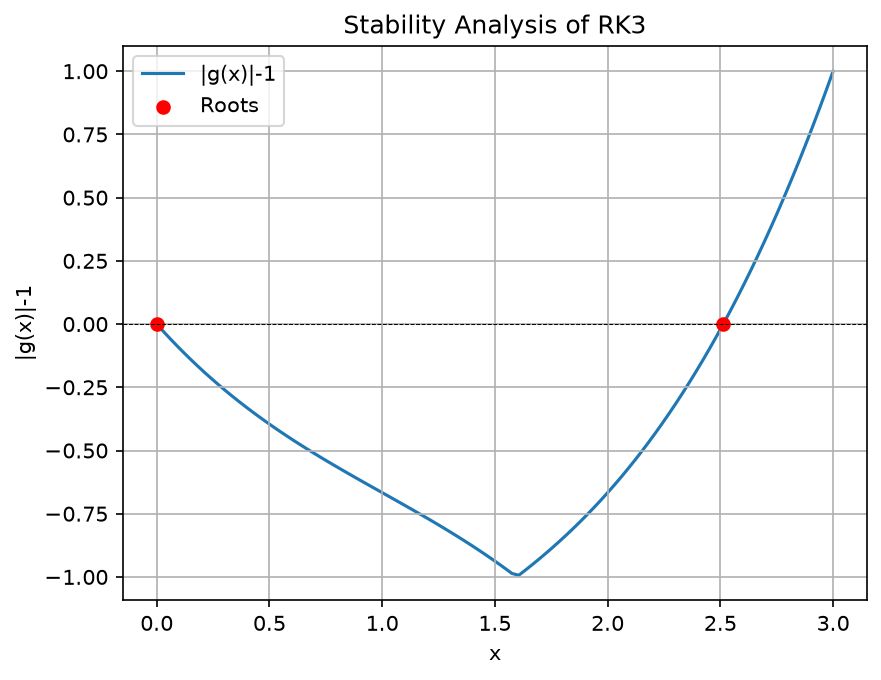

In [ ]:
def g(x):
    return 1-x+(x**2)/2-(x**3)/6
x = np.linspace(0, 3, 100)
roots_minus_1 = np.roots([1/6, -1/2, 1, -2]) 
roots_plus_1 = np.roots([1/6, -1/2, 1, 0])  
all_roots = np.concatenate((roots_minus_1, roots_plus_1))
real_roots = all_roots[np.isreal(all_roots)].real
y_roots = abs(g(real_roots))-1
plt.plot(x, np.abs(g(x)) - 1, label='|g(x)|-1', zorder=1)
plt.scatter(real_roots, y_roots, color='red', marker='o', label='Roots', zorder=2) # Using scatter plots all roots automatically

plt.xlabel('x')
plt.ylabel('|g(x)|-1')
plt.title('Stability Analysis of RK3')
plt.axhline(0, color='black', linewidth=0.5, linestyle='--')
plt.grid()
plt.legend()
plt.show()